# 绝热冷却与常数 Dpp 联合演化

$D_{pp}=D=1\ \mathrm{GV^2/yr}$，$a=(\nabla\cdot v)/3=0.01\ \mathrm{yr^{-1}}$。
刚度范围 0.1–200 GV，512 单元，时间步 0.001 yr；初始高斯谱中心 20 GV、标准差 2 GV。
比较 1、5、10、50、100 yr 的数值谱和解析谱。

对于 $q=dn/dR$，联合方程为
$$\partial_tq=\partial_R[aRq+D\partial_Rq-2Dq/R].$$
定义 $b=e^{-at}$、$S=D(1-e^{-2at})/a$，半无限域 $R>0$ 的解析核为
$$K(R,s,t)=\frac{R}{bs\sqrt{2\pi S}}
\left[e^{-(R-bs)^2/(2S)}-e^{-(R+bs)^2/(2S)}\right],\qquad
q(R,t)=\int_0^\infty K(R,s,t)q_0(s)\,ds.$$
解析谱按数值初态的分段常数重建积分，并取目标单元平均；保留两者原始归一化。
数值计算使用有限域 Outflow 边界，解析解使用原点正则、无穷远衰减条件，边界附近可能存在差异。


In [1]:
from pathlib import Path
import subprocess
import tempfile
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

root = Path.cwd()
run_dir = tempfile.TemporaryDirectory(prefix="momentum_joint_")
run_path = Path(run_dir.name)
exe = run_path / "test_momentum_joint"
subprocess.run(["c++", "-std=c++20", "-O2", "-I", str(root),
                str(root/"test_momentum_joint.cpp"), str(root/"momentum_solver.cpp"),
                str(root/"field.cpp"), "-o", str(exe)], check=True)
subprocess.run([str(exe)], cwd=run_path, check=True)
times = (1, 5, 10, 50, 100)
spectra = {t: np.fromfile(run_path/f"momentum_joint_t{t}.bin",
                          dtype=np.float64).reshape(-1, 5) for t in times}
a, D = 0.01, 1.0


In [2]:
def analytic_average(data, time):
    lo, hi, R, initial, numerical = data.T
    z, w = leggauss(8)
    s = ((lo+hi)[:,None]/2 + (hi-lo)[:,None]*z/2).ravel()
    mass = ((hi-lo)[:,None]*w/2 * initial[:,None]).ravel()
    mask = mass != 0
    s, mass = s[mask], mass[mask]
    b = np.exp(-a*time)
    S = -D*np.expm1(-2*a*time)/a
    m = b*s
    average = np.empty(len(R))
    for k in range(len(R)):
        r = ((lo[k]+hi[k])/2 + (hi[k]-lo[k])*z/2)[:,None]
        # Stable difference between the Gaussian and its image at negative R.
        kernel = (r/m/np.sqrt(2*np.pi*S) * np.exp(-(r-m)**2/(2*S))
                  * (-np.expm1(-2*r*m/S)))
        average[k] = np.sum((kernel @ mass)*w)/2
    return average

analytic = {t: analytic_average(spectra[t], t) for t in times}


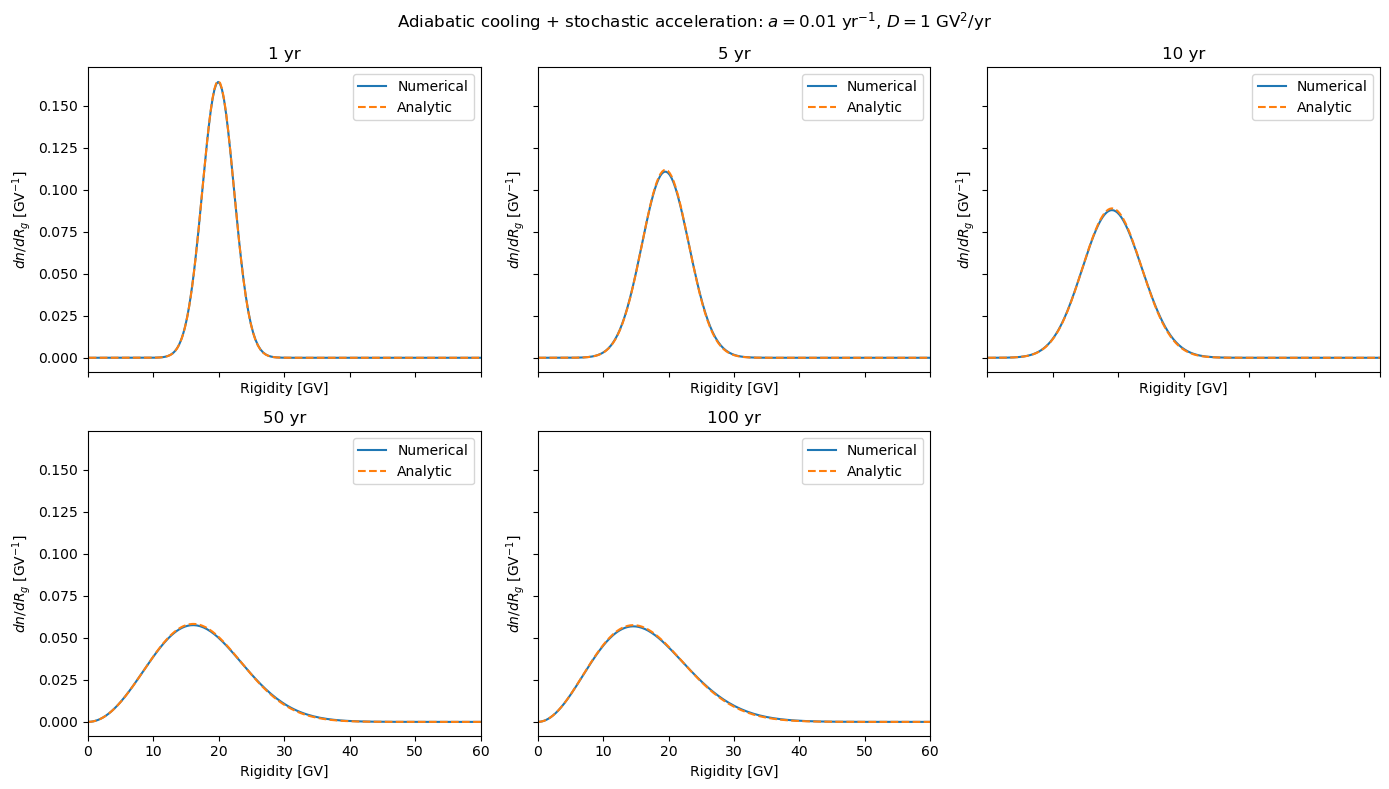

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
for ax, t in zip(axes.flat, times):
    data = spectra[t]
    ax.plot(data[:,2], data[:,4], label="Numerical", color="tab:blue")
    ax.plot(data[:,2], analytic[t], "--", label="Analytic", color="tab:orange")
    ax.set_title(f"{t} yr")
    ax.set_xlim(0, 60)
    ax.set_xlabel("Rigidity [GV]")
    ax.set_ylabel(r"$dn/dR_g$ [GV$^{-1}$]")
    ax.legend()
axes.flat[-1].set_visible(False)
fig.suptitle(r"Adiabatic cooling + stochastic acceleration: $a=0.01$ yr$^{-1}$, $D=1$ GV$^2$/yr")
plt.tight_layout()
plt.show()
